<a href="https://colab.research.google.com/github/xtianu/Docencia/blob/main/UPC/DAPR/S4.%20Flipped%20classroom/S4_FlippedClassroom_Exercises_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

**Student:** Arnaud Jaucot de Gronckel  
**Course:** Data Analysis & Pattern Recognition  
**Assignment:** Flipped Classroom S4 – Clustering Analysis  
**GitHub:** https://github.com/arnaudJaucot/UPC-DAPR-Labs


# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values before cleaning:
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64

Missing values after cleaning:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64

Rows kept: 342 / 344

Scaled means (approximately 0):
bill_length_mm       0.0
bill_depth_mm       -0.0
flipper_length_mm   -0.0
body_mass_g          0.0
dtype: float64

Scaled standard deviations (approximately 1):
bill_length_mm       1.0
bill_depth_mm        1.0
flipper_length_mm    1.0
body_mass_g          1.0
dtype: float64


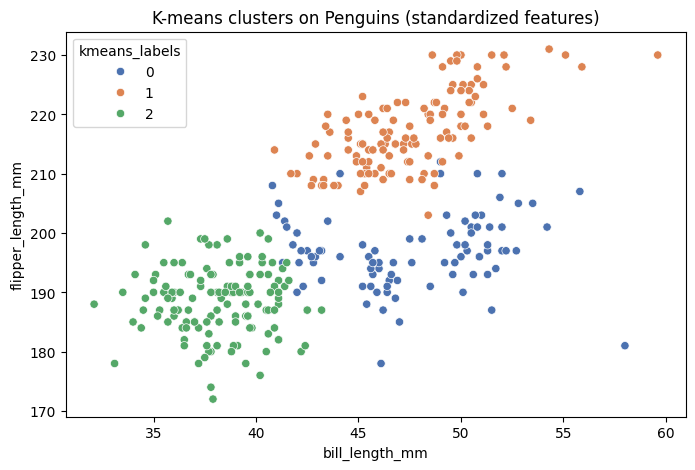

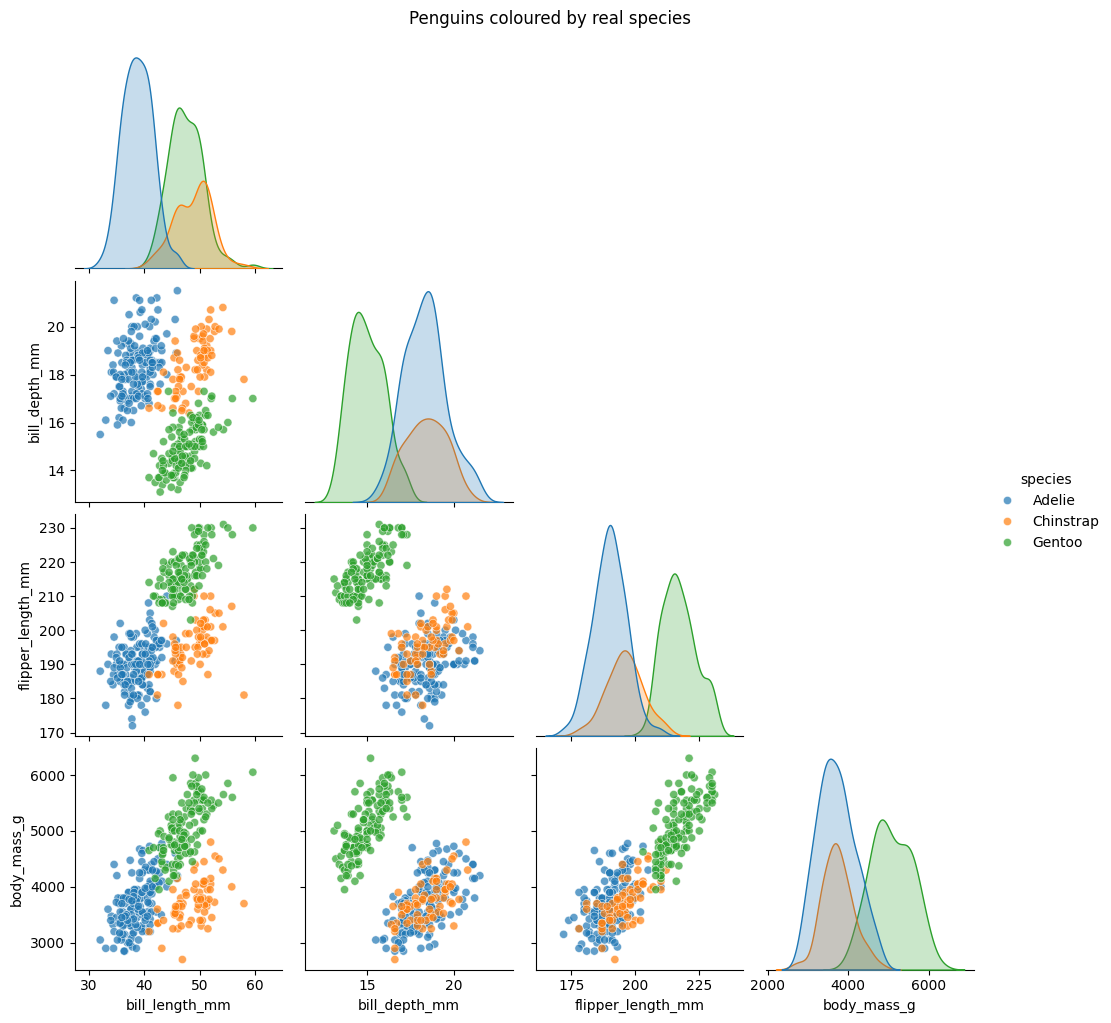

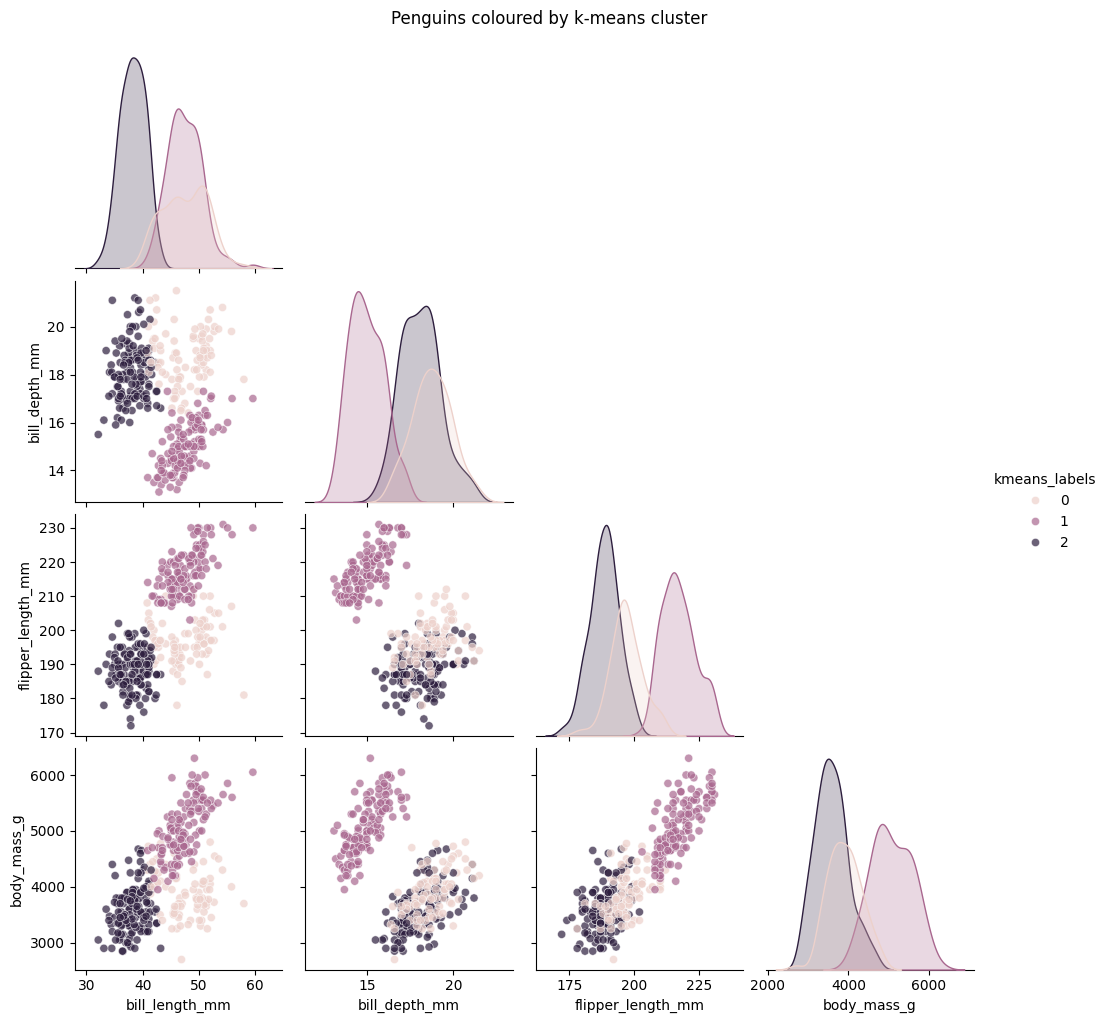

Species encoding: {'Adelie': np.int64(0), 'Chinstrap': np.int64(1), 'Gentoo': np.int64(2)}

Confusion matrix (rows = real species, columns = k-means clusters):
[[ 24   0 127]
 [ 63   0   5]
 [  0 123   0]]

Adjusted Rand Score: 0.793

Species vs cluster crosstab:
kmeans_labels   0    1    2
species                    
Adelie         24    0  127
Chinstrap      63    0    5
Gentoo          0  123    0

ARI with STANDARDIZED variables: 0.793
ARI with RAW variables:          0.314
Normalization improves agreement with the real species for this run.


In [7]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) Check missing values, then remove only rows that are incomplete
# for the four numeric variables used in clustering.
print("Missing values before cleaning:")
print(penguins[num_cols].isna().sum())

penguins_clean = penguins.dropna(subset=num_cols).copy()

print("\nMissing values after cleaning:")
print(penguins_clean[num_cols].isna().sum())
print(f"\nRows kept: {len(penguins_clean)} / {len(penguins)}")

# b) Standardize the four numeric variables.
# This is important because k-means is based on Euclidean distance:
# without scaling, body_mass_g would dominate simply because its
# numerical values are much larger than the measurements in millimetres.
scaler = StandardScaler()
penguins_scaled = scaler.fit_transform(penguins_clean[num_cols])
penguins_scaled_df = pd.DataFrame(
    penguins_scaled,
    columns=num_cols,
    index=penguins_clean.index
)

print("\nScaled means (approximately 0):")
print(penguins_scaled_df.mean().round(3))
print("\nScaled standard deviations (approximately 1):")
print(penguins_scaled_df.std(ddof=0).round(3))

# c) K-means with three clusters.
# random_state makes the result reproducible.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(penguins_scaled_df)

# d) Store labels in the interpretable, unscaled dataframe and visualize.
penguins_clean['kmeans_labels'] = kmeans_labels

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='kmeans_labels',
    palette='deep'
)
plt.title('K-means clusters on Penguins (standardized features)')
plt.show()

sns.pairplot(
    penguins_clean,
    vars=num_cols,
    hue='species',
    corner=True,
    plot_kws={'alpha': 0.7, 's': 35}
)
plt.suptitle('Penguins coloured by real species', y=1.02)
plt.show()

sns.pairplot(
    penguins_clean,
    vars=num_cols,
    hue='kmeans_labels',
    corner=True,
    plot_kws={'alpha': 0.7, 's': 35}
)
plt.suptitle('Penguins coloured by k-means cluster', y=1.02)
plt.show()

# e) Compare the unsupervised clusters with the known species.
# Cluster numbers (0,1,2) are arbitrary, so the Adjusted Rand Score is
# especially useful because it is invariant to a permutation of labels.
encoder = LabelEncoder()
species_encoded = encoder.fit_transform(penguins_clean['species'])

cm = confusion_matrix(species_encoded, kmeans_labels)
ari = adjusted_rand_score(species_encoded, kmeans_labels)

print("Species encoding:", dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))
print("\nConfusion matrix (rows = real species, columns = k-means clusters):")
print(cm)
print(f"\nAdjusted Rand Score: {ari:.3f}")

# A crosstab is easier to read because it keeps the real species names.
print("\nSpecies vs cluster crosstab:")
print(pd.crosstab(penguins_clean['species'], penguins_clean['kmeans_labels']))

# f) Compare with k-means on raw (unscaled) variables to test the effect of scaling.
kmeans_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
raw_labels = kmeans_raw.fit_predict(penguins_clean[num_cols])
raw_ari = adjusted_rand_score(species_encoded, raw_labels)

print(f"\nARI with STANDARDIZED variables: {ari:.3f}")
print(f"ARI with RAW variables:          {raw_ari:.3f}")

if ari > raw_ari:
    print("Normalization improves agreement with the real species for this run.")
elif ari < raw_ari:
    print("Normalization reduces agreement with the real species for this run.")
else:
    print("Normalization gives the same ARI for this run.")


### Exercise 1 — interpretation
K-means gives a reasonably good approximation of the real penguin species, with an Adjusted Rand Score of 0.793 after standardization. The result is not perfect, but the main structure of the dataset is recovered quite well.  
The crosstab shows that Gentoo is perfectly isolated in one cluster (123/123), while Adelie is mostly grouped in another cluster (127 observations). The main overlap occurs with Chinstrap, where most observations are assigned to a different cluster and a few are mixed with Adelie.  
Standardization has a strong positive effect here: the ARI increases from 0.314 on the raw variables to 0.793 on the standardized variables. This makes sense because body_mass_g has a much larger numerical scale than the other measurements and would otherwise dominate the Euclidean distances used by k-means.


## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Any missing values in X? False

Standardized X:
[[-1.    -0.234]
 [-1.     0.701]
 [-1.    -1.168]
 [ 1.     1.635]
 [ 1.     0.234]
 [ 1.    -1.168]]

Manual distance X[0] -> X[3]: 5.656854249492381
NumPy check:                    5.656854249492381


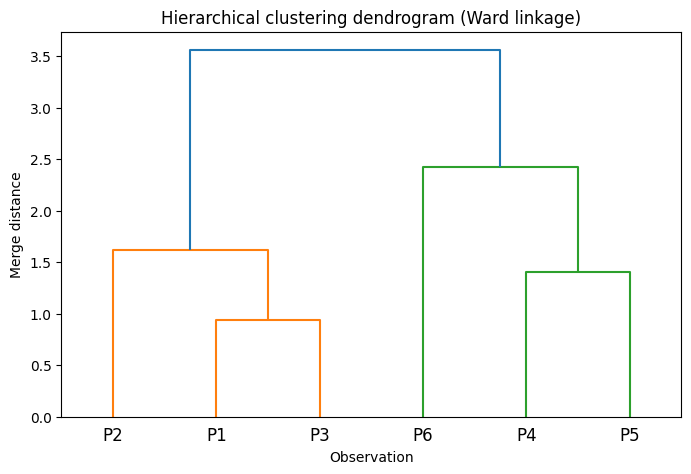


Agglomerative labels: [1 1 1 0 0 0]
K-means labels:        [0 0 0 1 1 1]
Adjusted Rand Score between the two clusterings: 1.000


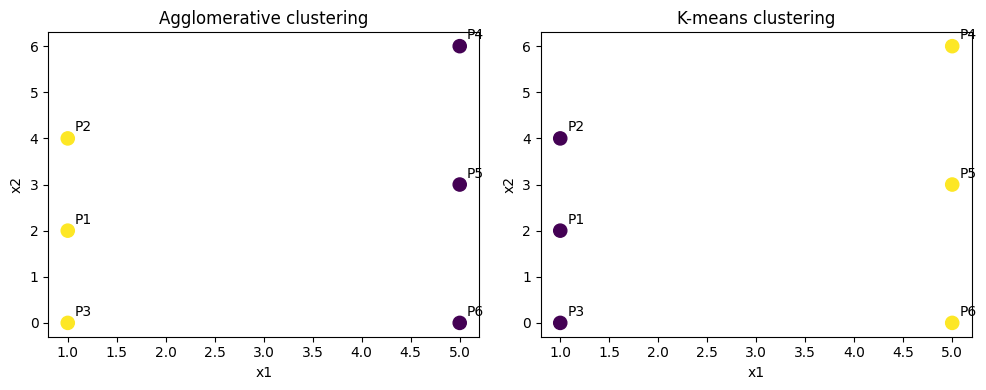


Agglomerative cluster sizes: {1: 3, 0: 3}
K-means cluster sizes:        {0: 3, 1: 3}


In [8]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.cluster import adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) Check for missing values.
print("Any missing values in X?", np.isnan(X).any())

# b) Standardize before using distance-based clustering.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nStandardized X:")
print(np.round(X_scaled, 3))

# c) Plain-Python Euclidean distance:
# sqrt(sum((p1_i - p2_i)^2)) using only a for loop.
def euclidean_distance(p1, p2):
    squared_sum = 0
    for i in range(len(p1)):
        squared_sum += (p1[i] - p2[i]) ** 2
    return squared_sum ** 0.5

manual_distance = euclidean_distance(X[0], X[3])
numpy_distance = np.linalg.norm(X[0] - X[3])

print("\nManual distance X[0] -> X[3]:", manual_distance)
print("NumPy check:                   ", numpy_distance)

# d) Agglomerative clustering + dendrogram.
# Ward linkage is consistent with a variance-minimizing, Euclidean approach.
agglo = AgglomerativeClustering(n_clusters=2, linkage='ward')
agglo_labels = agglo.fit_predict(X_scaled)

Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(8, 5))
dendrogram(Z, labels=[f'P{i+1}' for i in range(len(X))])
plt.title('Hierarchical clustering dendrogram (Ward linkage)')
plt.xlabel('Observation')
plt.ylabel('Merge distance')
plt.show()

# e) K-means on the same standardized data.
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# f) Compare partitions.
print("\nAgglomerative labels:", agglo_labels)
print("K-means labels:       ", kmeans_labels)

partition_ari = adjusted_rand_score(agglo_labels, kmeans_labels)
print(f"Adjusted Rand Score between the two clusterings: {partition_ari:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].scatter(X[:, 0], X[:, 1], c=agglo_labels, s=90)
for i, (x, y) in enumerate(X):
    axes[0].annotate(f'P{i+1}', (x, y), xytext=(5, 5), textcoords='offset points')
axes[0].set_title('Agglomerative clustering')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('x2')

axes[1].scatter(X[:, 0], X[:, 1], c=kmeans_labels, s=90)
for i, (x, y) in enumerate(X):
    axes[1].annotate(f'P{i+1}', (x, y), xytext=(5, 5), textcoords='offset points')
axes[1].set_title('K-means clustering')
axes[1].set_xlabel('x1')
axes[1].set_ylabel('x2')

plt.tight_layout()
plt.show()

# Important: cluster IDs are arbitrary.
# Even if one method calls a group "0" and the other calls the same group "1",
# the partitions can still be identical. ARI = 1 means identical partitions.

# g) Count observations per cluster using a plain dictionary.
def cluster_sizes(labels):
    counts = {}
    for label in labels:
        label = int(label)
        if label in counts:
            counts[label] += 1
        else:
            counts[label] = 1
    return counts

print("\nAgglomerative cluster sizes:", cluster_sizes(agglo_labels))
print("K-means cluster sizes:       ", cluster_sizes(kmeans_labels))


### Exercise 2 — interpretation

Agglomerative clustering and k-means return different numerical labels, but this is only because cluster IDs are arbitrary. They produce exactly the same partition of the six observations, confirmed by an Adjusted Rand Score of 1.000. The manually implemented Euclidean distance also matches NumPy’s result, confirming that the custom function is correct.

---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Missing values before cleaning:
carat    0
depth    0
table    0
price    0
dtype: int64

Missing values after cleaning:
carat    0
depth    0
table    0
price    0
dtype: int64

Rows kept: 1000


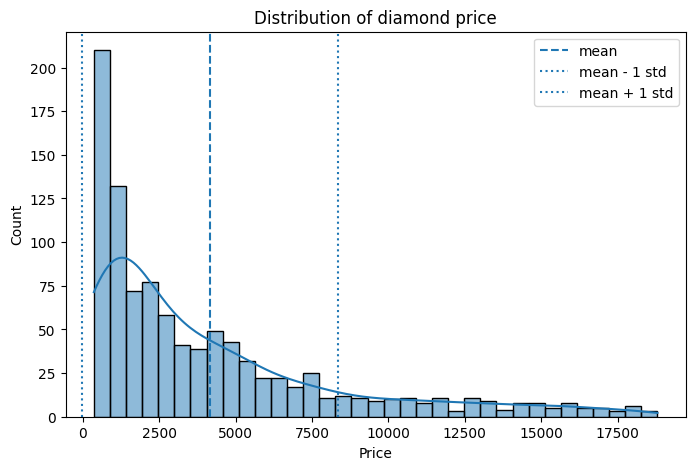

Price mean = 4165.15
Price standard deviation = 4190.10


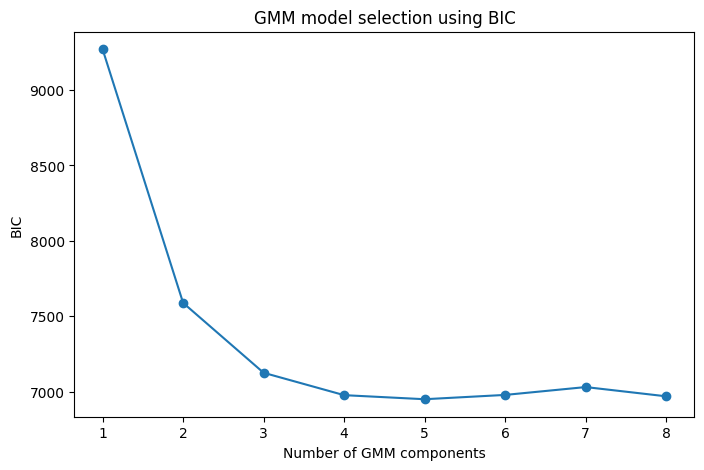

Best number of components according to BIC: 5


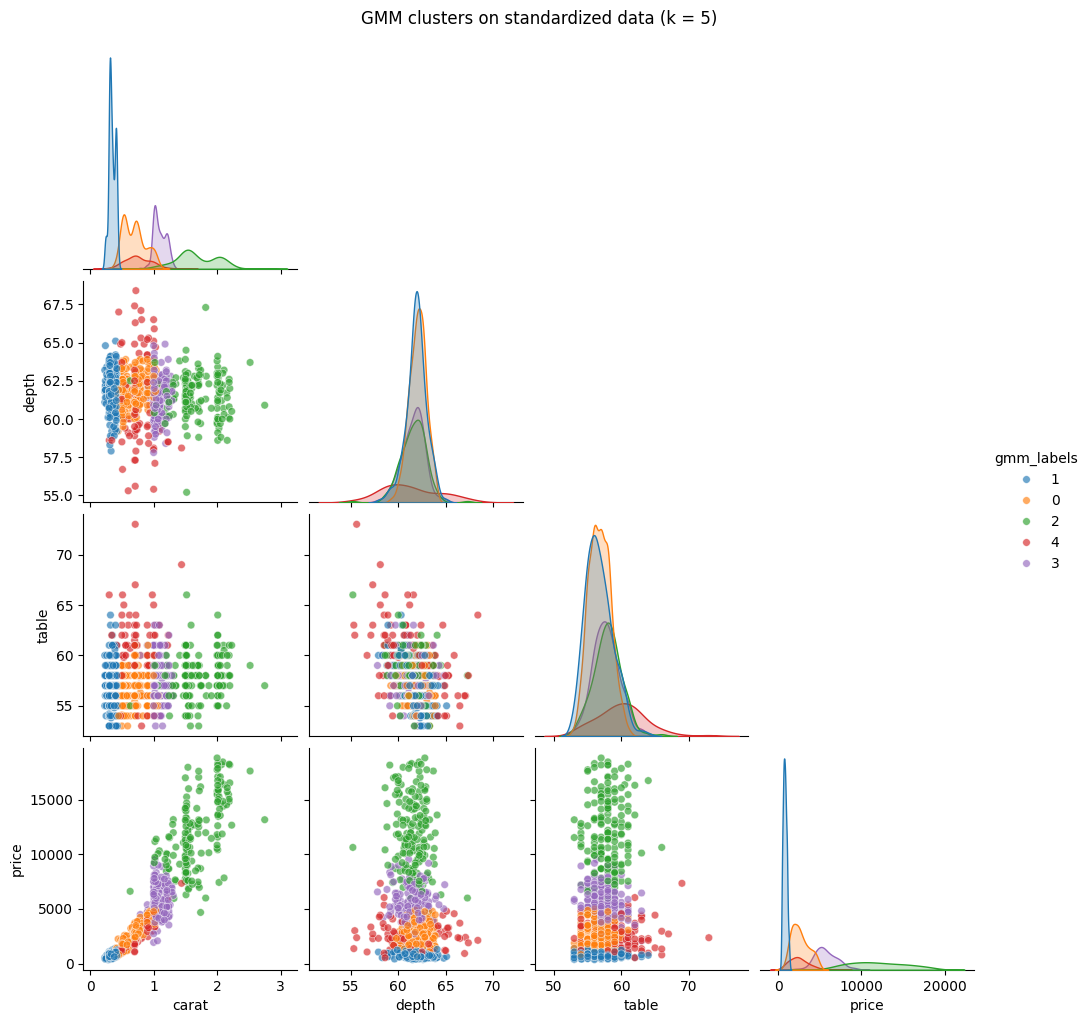

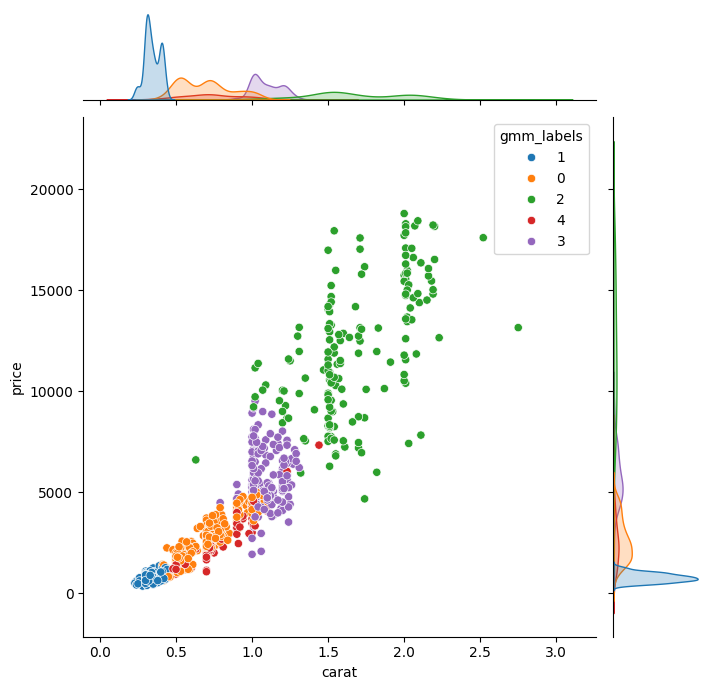


Best number of components with STANDARDIZED data: 5
Best number of components with RAW data:          5
Normalization did not change the BIC-optimal number of components in this sample.


In [6]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
diamond_cols = ['carat', 'depth', 'table', 'price']

# a) Select numeric variables and clean missing values.
diamonds_num = diamonds[diamond_cols].copy()

print("Missing values before cleaning:")
print(diamonds_num.isna().sum())

diamonds_num = diamonds_num.dropna().copy()

print("\nMissing values after cleaning:")
print(diamonds_num.isna().sum())
print(f"\nRows kept: {len(diamonds_num)}")

# b) Inspect the price distribution.
price_mean = diamonds_num['price'].mean()
price_std = diamonds_num['price'].std()

plt.figure(figsize=(8, 5))
sns.histplot(diamonds_num['price'], bins=35, kde=True)
plt.axvline(price_mean, linestyle='--', label='mean')
plt.axvline(price_mean - price_std, linestyle=':', label='mean - 1 std')
plt.axvline(price_mean + price_std, linestyle=':', label='mean + 1 std')
plt.xlabel('Price')
plt.title('Distribution of diamond price')
plt.legend()
plt.show()

print(f"Price mean = {price_mean:.2f}")
print(f"Price standard deviation = {price_std:.2f}")

# c) Standardize all four variables.
scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num[diamond_cols])

# d) Fit GMMs with 1..8 components and compute BIC.
bic = []
n_components_range = range(1, 9)

for n in n_components_range:
    gmm = mixture.GaussianMixture(
        n_components=n,
        covariance_type='full',
        random_state=42,
        n_init=3
    )
    gmm.fit(diamonds_scaled)
    bic.append(gmm.bic(diamonds_scaled))

plt.figure(figsize=(8, 5))
plt.plot(list(n_components_range), bic, marker='o')
plt.xlabel('Number of GMM components')
plt.ylabel('BIC')
plt.title('GMM model selection using BIC')
plt.xticks(list(n_components_range))
plt.show()

# e) Lowest BIC = preferred model among the candidates.
best_n = list(n_components_range)[int(np.argmin(bic))]
print("Best number of components according to BIC:", best_n)

final_gmm = mixture.GaussianMixture(
    n_components=best_n,
    covariance_type='full',
    random_state=42,
    n_init=3
)
gmm_labels = final_gmm.fit_predict(diamonds_scaled)

# f) Add the labels to the unscaled dataframe for interpretable plots.
diamonds_num['gmm_labels'] = gmm_labels.astype(str)

sns.pairplot(
    diamonds_num,
    vars=diamond_cols,
    hue='gmm_labels',
    corner=True,
    plot_kws={'alpha': 0.65, 's': 30}
)
plt.suptitle(f'GMM clusters on standardized data (k = {best_n})', y=1.02)
plt.show()

sns.jointplot(
    data=diamonds_num,
    x='carat',
    y='price',
    hue='gmm_labels',
    height=7
)
plt.show()

# g) Directly test whether standardization changes model selection.
# This extra comparison answers the final question quantitatively.
raw_X = diamonds_num[diamond_cols].to_numpy()
bic_raw = []

for n in n_components_range:
    gmm_raw = mixture.GaussianMixture(
        n_components=n,
        covariance_type='full',
        random_state=42,
        n_init=3
    )
    gmm_raw.fit(raw_X)
    bic_raw.append(gmm_raw.bic(raw_X))

best_raw_n = list(n_components_range)[int(np.argmin(bic_raw))]

print(f"\nBest number of components with STANDARDIZED data: {best_n}")
print(f"Best number of components with RAW data:          {best_raw_n}")

if best_raw_n == best_n:
    print("Normalization did not change the BIC-optimal number of components in this sample.")
else:
    print(
        "Normalization changed the BIC-optimal number of components "
        f"from {best_raw_n} (raw) to {best_n} (standardized)."
    )


### Exercise 3 — interpretation

The BIC reaches its minimum for 5 Gaussian components, so the selected GMM contains 5 clusters. This seems reasonable when looking at the pairplot, although the clusters overlap and I would not necessarily have guessed exactly five groups by visual inspection alone. The strongest separation appears to be related to the relationship between carat and price.  
Fitting the GMM on the raw data also gives an optimal number of 5 components. Therefore, in this sample, standardization did not change the BIC-optimal number of clusters, although it remains useful because the variables have very different numerical scales.


---

### Notes for explaining the solution in class

- **Why standardize?** All three clustering approaches used here depend directly or indirectly on distances / covariance. Standardization prevents variables with large numerical scales from dominating.
- **K-means:** fixed `K`, centroid-based, minimizes within-cluster squared distances; works best with roughly compact / globular clusters.
- **Hierarchical agglomerative clustering:** starts from single observations and merges groups; the dendrogram lets us inspect the hierarchy and choose a cut level.
- **GMM:** models the data as a mixture of Gaussian distributions and gives probabilistic cluster assignments.
- **ARI:** compares two partitions while ignoring arbitrary cluster label names.
- **BIC:** model-selection criterion; among the tested GMMs, lower BIC is preferred because it balances fit and complexity.

AI assistance was used to help structure and verify the implementation. The reasoning for every major processing and modelling step is documented in the notebook so that the solution can be explained rather than simply executed.
